# 04 · The session risk model: who should get a full rescan?

Week 4 showed that partial checks, however well targeted, rarely find items skipped on purpose:
they are concealed outside the bags. Catching deliberate non-scanning comes down to **who gets a
full rescan**. This notebook builds the score that decides it.

**The discipline.** The model only learns from what a store can observe:
- **features**: the session's scan log, and the member's history from earlier trips (Nectar
  purchases, earlier SmartShop sessions, earlier rescan outcomes). No demographics, no channel, no
  time of day, no tenure (see section 6 for why).
- **labels**: what random **full** rescans found. Unbiased because selection was random, but
  scarce (2% of sessions). Partial rescans are not used: they rarely see concealed items.
- **selection**: label, feature set and model chosen by repeated cross-validation of *observable*
  value capture ("of the value found by held-out random full rescans, how much would our top 20%
  have caught?"). The hidden truth is used once, at the end.

In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from smartshop.basket.data import prepare
from smartshop.risk.evaluate import capture_curve, compare, floor_experiment, scores_for_test, truth
from smartshop.risk.features import NOT_FOR_SCORING
from smartshop.risk.model import (METRICS_PATH, MODEL_PATH, TRAIN_LAST_DAY, fit_oracle,
                                  load_features, observed_labels)
from smartshop.viz import BLUE, GREY, ORANGE, TEXT_2, pct, save, set_style, subtitle
from smartshop.warehouse import connect

set_style()
con = connect()
prepare(con)
df = load_features(con)
labels = observed_labels(con)
bundle = joblib.load(MODEL_PATH)
model, cols = bundle['model'], bundle['features']
metrics = json.loads(METRICS_PATH.read_text())
t = truth(con)

## 1. The labels a store actually has

In [2]:
tr = df[df.day <= TRAIN_LAST_DAY].merge(labels, on='basket_id')
pd.Series({
    'SmartShop sessions, training period': int((df.day <= TRAIN_LAST_DAY).sum()),
    'random full rescans (labels)': len(tr),
    'found anything': int((tr.found_missing_units > 0).sum()),
    'found $5+': int((tr.found_missing_value >= 5).sum()),
    'found $10+': int((tr.found_missing_value >= 10).sum()),
})

SmartShop sessions, training period    43874
random full rescans (labels)             939
found anything                           185
found $5+                                 41
found $10+                                21
dtype: int64

## 2. Honest selection on observable labels only

Repeated 5-fold cross-validation (10 repeats). The leading candidates are close: with labels this
scarce the store can barely tell them apart, which section 4 comes back to.

In [3]:
pd.DataFrame(metrics['selection']).head(8)

,label,features,model,cv_value_capture_top20
0,found anything,session+history+gap,logistic,0.6301
1,found anything,session+history,logistic,0.6272
2,found $5+,session+history+gap,logistic,0.6251
3,found anything,session,logistic,0.6237
4,found $5+,session+history,logistic,0.6073
5,found $5+,session,logistic,0.5757
6,found $10+,session,logistic,0.5619
7,found $10+,session+history+gap,logistic,0.5616


In [4]:
print('Chosen:', metrics['chosen'])
print(f'{len(cols)} scoring features; built but never scored on: {NOT_FOR_SCORING}')

Chosen: {'label': 'found anything', 'features': 'session+history+gap', 'model': 'logistic'}
27 scoring features; built but never scored on: ['is_app', 'hour_of_day', 'is_peak', 'prior_trips', 'prior_ss_sessions', 'days_since_first_ss', 'prior_rescans', 'prior_full_rescans']


## 3. Against the hidden truth (test period, days 501–711)

Flag the top 12% of sessions, the same share rescanned today. Baselines a store could use:
random (today), the biggest baskets, a rule of thumb (one point per red flag), and the single best
signal chosen on the same observable labels. The ceiling is the same features with a model
trained on the hidden truth for every session.

In [5]:
oracle = fit_oracle(df, t, cols)
test, scores = scores_for_test(df, labels, model, cols, oracle)
results = compare(test, scores, t, share=0.12)
results.round(3)

,auc_deliberate,ap_deliberate,deliberate_value_flagged,net_loss_flagged,deliberate_sessions_flagged,flagged_with_nothing_deliberate
method,,,,,,
Random (today),0.490,0.044,0.123,0.125,0.114,0.958
Biggest baskets,0.504,0.042,0.214,0.262,0.078,0.971
Rule of thumb (red-flag points),0.594,0.058,0.329,0.342,0.147,0.945
Best single signal (n_deletes),0.655,0.107,0.484,0.424,0.333,0.877
Risk model,0.655,0.126,0.509,0.515,0.314,0.884
Ceiling: trained on hidden truth,0.903,0.537,0.817,0.674,0.718,0.734


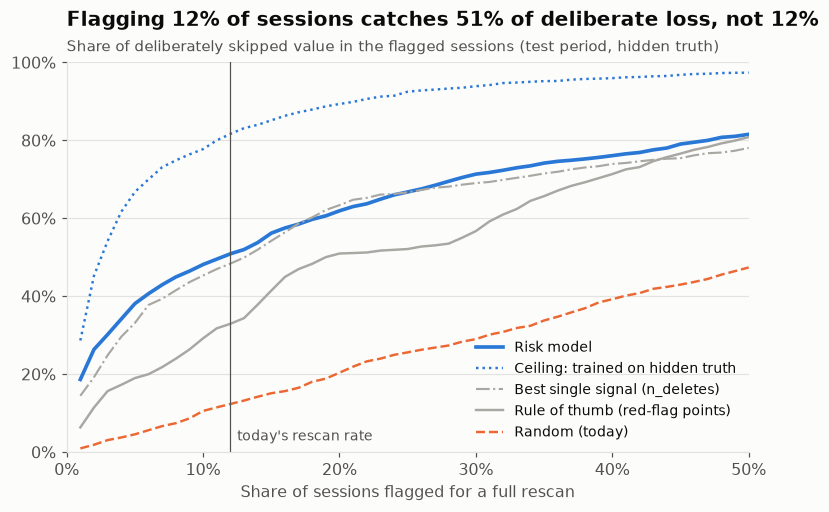

In [6]:
curve = capture_curve(test, scores, t)
fig, ax = plt.subplots(figsize=(8, 4.6))
best = [m for m in scores if m.startswith('Best single')][0]
style = [('Risk model', BLUE, '-', 2.4), ('Ceiling: trained on hidden truth', BLUE, ':', 1.6),
         (best, GREY, '-.', 1.4), ('Rule of thumb (red-flag points)', GREY, '-', 1.6),
         ('Random (today)', ORANGE, '--', 1.6)]
for name, color, ls, lw in style:
    d = curve[curve.method == name]
    ax.plot(d.share, d.captured, color=color, ls=ls, lw=lw, label=name)
ax.axvline(0.12, color=TEXT_2, lw=0.8)
ax.text(0.125, 0.03, "today's rescan rate", color=TEXT_2, fontsize=9)
ax.xaxis.set_major_formatter(pct())
ax.yaxis.set_major_formatter(pct())
ax.set_xlim(0, 0.5)
ax.set_ylim(0, 1)
ax.set_xlabel('Share of sessions flagged for a full rescan')
r = results.loc['Risk model', 'deliberate_value_flagged']
ax.set_title(f'Flagging 12% of sessions catches {r:.0%} of deliberate loss, not 12%')
subtitle(ax, 'Share of deliberately skipped value in the flagged sessions (test period, hidden truth)')
ax.legend(loc='lower right', fontsize=9)
save(fig, '11_risk_capture_curve')
fig

## 4. What more random full rescans would buy

Re-run history with a larger random *full*-rescan floor (same simulated shoppers and draws) and
train the chosen configuration on what those rescans would have found.

In [7]:
ch = metrics['chosen']
floors = floor_experiment(con, df, cols, ch['label'], ch['model'], floors=[0.02, 0.05, 0.10, 0.20])
summary = floors.groupby('floor').agg(
    labels=('n_labels', 'mean'), auc=('auc_deliberate', 'mean'),
    flagged=('deliberate_value_flagged', 'mean'), lo=('deliberate_value_flagged', 'min'),
    hi=('deliberate_value_flagged', 'max'))
summary.round(3)

,labels,auc,flagged,lo,hi
floor,,,,,
0.02,877.0,0.680,0.568,0.520,0.593
0.05,2193.0,0.698,0.590,0.545,0.619
0.10,4387.0,0.707,0.604,0.585,0.621
0.20,8774.0,0.706,0.617,0.608,0.624


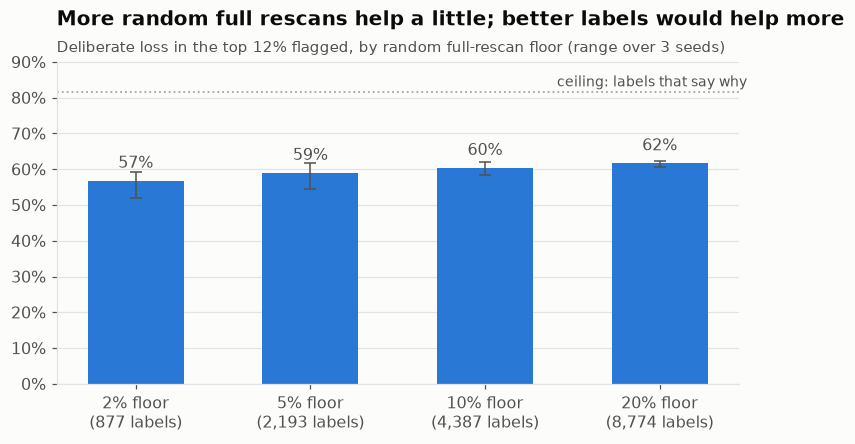

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(summary))
bars = ax.bar(x, summary.flagged, color=BLUE, width=0.55)
ax.errorbar(x, summary.flagged, yerr=[summary.flagged - summary.lo, summary.hi - summary.flagged],
            fmt='none', ecolor=TEXT_2, capsize=4, lw=1)
ax.bar_label(bars, labels=[f'{v:.0%}' for v in summary.flagged], padding=6, color=TEXT_2)
ax.set_xticks(x, [f'{f:.0%} floor\n({int(n):,} labels)' for f, n in zip(summary.index, summary.labels)])
ax.yaxis.set_major_formatter(pct())
ceiling = results.loc['Ceiling: trained on hidden truth', 'deliberate_value_flagged']
ax.set_ylim(0, 0.9)
ax.axhline(ceiling, color=GREY, ls=':', lw=1.2)
ax.text(len(x) - 0.5, ceiling + 0.015, 'ceiling: labels that say why', color=TEXT_2, fontsize=9, ha='right')
ax.set_title('More random full rescans help a little; better labels would help more')
subtitle(ax, 'Deliberate loss in the top 12% flagged, by random full-rescan floor (range over 3 seeds)')
save(fig, '12_value_of_random_floor')
fig

Different random draws of ~900 labels give quite different models (52–59% across seeds; the
actual history gave 51%), so a 2% floor is noisy as well as small. More labels of the same kind
help only a little on average. The ceiling is far higher because it is trained
on *why* items were missing; a rescan only records *that* they were, and most findings are honest
mistakes. Logging what kind of item was found (a high-risk line, say) is a cheap process change a
store could test; with today's few labels it did not clearly help here.

## 5. Every flag comes with reasons

A logistic model explains each decision: a feature's contribution is its coefficient times its
standardised value. A colleague sees the top reasons, not a number.

In [9]:
lr = model.steps[-1][1]
coef = pd.Series(lr.coef_[0], index=cols)
coef.reindex(coef.abs().sort_values(ascending=False).index).head(10).round(3)

max_gap_min        1.132
min_per_unit      -0.837
scanned_units      0.749
units_vs_usual     0.457
first_scan_frac    0.445
scanned_value      0.419
gap_cv             0.327
mean_unit_price   -0.310
m_delete_rate      0.261
n_products        -0.219
dtype: float32

In [10]:
readable = {
    'n_deletes': 'items deleted this shop', 'delete_rate': 'deletions per item',
    'm_delete_rate': 'usually deletes a lot', 'max_gap_min': 'long pause between scans',
    'gap_cv': 'irregular scanning pace', 'prior_found_rate': 'earlier rescans found items',
    'prior_found': 'earlier rescans found items', 'prior_full_found': 'earlier full rescan found items',
    'hr_value_share': 'many high-risk items', 'hr_share_gap': 'fewer high-risk items than usual',
    'min_per_unit': 'slow for items scanned', 'scanned_value': 'large basket value',
    'scanned_units': 'many items', 'gap_per_unit': 'basket looks incomplete',
    'gap_value': 'basket looks incomplete', 'duration_min': 'long shop',
    'first_scan_frac': 'late first scan', 'late_share': 'many scans at the end',
    'units_vs_usual': 'more items than usual', 'm_min_per_unit': 'usually slow for items scanned',
}
Xt = model[:-1].transform(test[cols])
contrib = pd.DataFrame(Xt * lr.coef_[0], columns=cols)
p = model.predict_proba(test[cols])[:, 1]
for i in np.argsort(-p)[:3]:
    top3 = contrib.iloc[i].sort_values(ascending=False).head(3).index
    print(f'score {p[i]:.2f}: ' + '; '.join(dict.fromkeys(readable.get(k, k) for k in top3)))

score 0.99: long pause between scans; many items; more items than usual
score 0.99: usually deletes a lot; long pause between scans; irregular scanning pace
score 0.99: long pause between scans; many items; irregular scanning pace


## 6. Fairness preview

Being flagged is an adverse outcome. Raw flag rates can differ because groups contain different
amounts of deliberate non-scanning, so the main check is the **honest-shopper stop rate**: among
sessions with nothing skipped on purpose, how often each group is flagged (top 12%). A ratio below
0.8 between the lowest and highest group breaches the four-fifths rule of thumb. Demographics are
used here only. Intervals resample *members*: a group's sessions come from few households.

**What the first version of this check found, and what was fixed.** The first model flagged
handset users, evening shoppers and new SmartShop users far more often, although none of these
changes behaviour in the simulation. With so few labels the model had learned spurious effects of
channel and time of day, and tenure features (trips, sessions and rescans so far) made newcomers
look unusual. All three were removed from scoring, and missing history is now filled with typical
values, so a new user is scored as typical, not suspicious.

In [11]:
tt = test[['basket_id', 'member_id', 'prior_ss_sessions', 'channel', 'is_peak']].merge(t, on='basket_id')
k = int(np.ceil(0.12 * len(tt)))
tt['flag'] = False
tt.loc[np.argsort(-scores['Risk model'])[:k], 'flag'] = True
demo = con.sql('SELECT * FROM staging.stg_member_demographics').df()
tt = tt.merge(demo, on='member_id', how='left')
tt['new_smartshop_user'] = tt.prior_ss_sessions < 5
groups = {'channel': 'channel', 'new SmartShop user': 'new_smartshop_user', 'evening peak': 'is_peak',
          'age group': 'age_group', 'household size': 'household_size', 'income level': 'income_level'}
rng = np.random.default_rng(0)

def stop_ratio(d, col):
    r = d.groupby(col).flag.mean()
    return r.min() / r.max()

rows = []
for label, col in groups.items():
    d = tt.dropna(subset=[col])
    d = d[~d.deliberate]
    big = d.groupby(col).size()
    d = d[d[col].isin(big[big >= 200].index)]
    members = d.member_id.unique()
    boot = [stop_ratio(pd.DataFrame({'member_id': rng.choice(members, len(members))}).merge(d, on='member_id'), col)
            for _ in range(300)]
    rows.append({'attribute': label, 'groups': d[col].nunique(),
                 'fewest households in a group': d.groupby(col).member_id.nunique().min(),
                 'honest-stop ratio': stop_ratio(d, col),
                 'CI low': np.percentile(boot, 2.5), 'CI high': np.percentile(boot, 97.5)})
fair = pd.DataFrame(rows).set_index('attribute')
fair.round(3)

,groups,fewest households in a group,honest-stop ratio,CI low,CI high
attribute,,,,,
channel,2,1033,0.978,0.858,0.996
new SmartShop user,2,687,0.974,0.817,0.998
evening peak,2,2016,0.985,0.906,0.999
age group,6,46,0.404,0.268,0.555
household size,5,53,0.591,0.442,0.702
income level,11,11,0.321,0.157,0.440


In [12]:
d = tt.dropna(subset=['age_group'])
d = d[~d.deliberate].merge(test[['basket_id', 'scanned_units', 'n_deletes']], on='basket_id')
d.groupby('age_group').agg(honest_stop_rate=('flag', 'mean'), avg_items=('scanned_units', 'mean'),
                           avg_deletes=('n_deletes', 'mean'), households=('member_id', 'nunique')).round(3)

,honest_stop_rate,avg_items,avg_deletes,households
age_group,,,,
Age Group1,0.091,16.040001,0.258,46
Age Group2,0.148,21.872000,0.354,142
Age Group3,0.145,21.829000,0.322,193
Age Group4,0.119,20.205000,0.297,288
Age Group5,0.089,18.146999,0.206,59
Age Group6,0.060,16.704000,0.313,72


Channel, new users and evening shoppers now pass. Age, household size and income do not: honest
households with bigger baskets are stopped more, and groups with few households swing on a
handful of habits. This is a **review item, not proof** (some groups have very few households),
and it is carried forward: week 6 adds a cap on how often any member can be rescanned, and week 10
runs the full check.

## Findings

| # | Finding | Implication |
|---|---|---|
| 1 | Only 939 random full rescans in the training period, 185 of which found anything | Label scarcity is the binding constraint, as in a real store |
| 2 | Chosen on observable labels only: "found anything", session + history + basket gap, logistic regression; the leading candidates are close | Honest selection; the truth played no part |
| 3 | Flagging 12% of sessions catches 51% of deliberately skipped value and 52% of net loss (random: 12%) | About 4x today's random selection at the same rescan rate |
| 4 | Store-style rules: biggest baskets 21%, red-flag points 33%, best single signal (deletions) 48% of deliberate value and 42% of net loss | Combining weak signals beats every rule, most clearly on total loss |
| 5 | A 5–20% random full floor adds only 2–5 points; a model trained on *why* items were missing reaches 82% | The bottleneck is label quality (rescans record that, not why), more than label count |
| 6 | First fairness check failed on channel, time of day and new users; fixed by removing those features and tenure. Honest-stop gaps remain for age, household size and income | Review items carried into the policy (per-member caps) and the full check (week 10) |

**Caveat.** Signal strengths come from the simulator's assumptions (deletions, pauses, habits),
softened so no single habit is a fingerprint. Week 8 tests conclusions under weaker signals.